# RNN lab: next-word prediction on Shakespeare's Sonnets
**Name:** Mikail Achmad  **Student ID (NIM):** 23026

Rules: PyTorch/NumPy/Python docs are allowed. Chatbots, code assistants and copying from classmates are not.
Your configuration (below) is generated from your NIM, so your numbers will differ from your neighbour's.
Cells marked **TODO** are yours to write. Cells marked **CHECK** run without edits and tell you whether your
code is right, so you never need outside help to know if you are on track.

In [1]:
import re, math, random, collections
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

NIM = 23026          # <-- type your student ID here (digits only)
assert NIM != 0, "Set NIM first"

In [2]:
def make_config(nim):
    rng = random.Random(nim)
    return dict(
        seq_len    = rng.choice([10, 15, 20]),        # words the RNN reads per training window
        hidden     = rng.choice([64, 96, 128]),      # size of the hidden state
        emb        = 64,
        lr         = rng.choice([0.002, 0.003, 0.004]),
        batch      = 64,
        epochs     = 8,
        test_start = rng.randrange(0, 146),           # 8 consecutive sonnets are held out for testing
        prompt     = rng.choice([["shall", "i", "compare"], ["when", "i", "do"], ["my", "love", "is"],
                                 ["thy", "sweet", "love"], ["o", "that", "time"], ["love", "is", "not"]]),
        seed       = nim % 10000,
    )

    # return dict(
    #     seq_len    = 20,
    #     hidden     = 128,
    #     emb        = 64,
    #     lr         = rng.choice([0.003]),
    #     batch      = 64,
    #     epochs     = 8,
    #     test_start = 32,
    #     # prompt     = rng.choice([["shall", "i", "compare"], ["when", "i", "do"], ["my", "love", "is"],
    #     #                          ["thy", "sweet", "love"], ["o", "that", "time"], ["love", "is", "not"]]),
    #     prompt = ['o', 'that', 'time'],
    #     seed       = 3026,
    # )

cfg = make_config(NIM)
torch.manual_seed(cfg["seed"]); random.seed(cfg["seed"]); np.random.seed(cfg["seed"])
print(cfg)

{'seq_len': 20, 'hidden': 128, 'emb': 64, 'lr': 0.003, 'batch': 64, 'epochs': 8, 'test_start': 32, 'prompt': ['o', 'that', 'time'], 'seed': 3026}


## Step 0: Load the data (provided)
154 sonnets, each 14 lines. Headers are Roman numerals alone on a line. If GitHub is blocked, use the `sonnets.txt` from the LMS.

In [3]:
import os, urllib.request
URL = "https://raw.githubusercontent.com/martin-gorner/tensorflow-rnn-shakespeare/master/shakespeare/sonnets.txt"
if os.path.exists("sonnets.txt"):
    raw = open("sonnets.txt", encoding="utf-8").read()
else:
    raw = urllib.request.urlopen(URL).read().decode("utf-8")
parts = re.split(r'^\s*([IVXLC]+)\.\s*$', raw, flags=re.M)
sonnets = [parts[i].strip() for i in range(2, len(parts), 2)]
print(len(sonnets), "sonnets")           # expect 154
print(sonnets[17][:120])

154 sonnets
Shall I compare thee to a summer's day?
Thou art more lovely and more temperate:
Rough winds do shake the darling buds o


## Step 1: Tokenize  *(TODO 1)*
Turn text into a list of tokens: lowercase **words** (letters and apostrophes, so `beauty's` stays one token) and the
punctuation marks `, . ; : ! ?` as separate tokens. Everything else (hyphens, brackets, digits) is dropped.

In [4]:
def tokenize(text):
    # TODO 1
    return re.findall(r"[a-z']+|[,.;:!?]", text.lower())

In [5]:
# CHECK 1
assert tokenize("Thou art, O Love's child!") == ['thou', 'art', ',', 'o', "love's", 'child', '!'], tokenize("Thou art, O Love's child!")
assert tokenize("A-b (c)") == ['a', 'b', 'c']
print("CHECK 1 passed")

CHECK 1 passed


## Step 2: Split by poem, build the vocabulary  *(TODO 2)*
The test set is 8 consecutive sonnets chosen by your config. **Build the vocabulary from the training poems only.**
Keep words that appear at least twice; everything else becomes `<unk>`. Index 0 must be `<unk>` and index 1 `<eos>`.
Each poem ends with an `<eos>` token (already added for you).

In [6]:
from collections import Counter

test_ids = set(range(cfg["test_start"], cfg["test_start"] + 8))
train_poems = [s for i, s in enumerate(sonnets) if i not in test_ids]
test_poems  = [s for i, s in enumerate(sonnets) if i in test_ids]

def poems_to_tokens(poems):
    out = []
    for p in poems:
        out += tokenize(p) + ["<eos>"]
    return out
train_tokens, test_tokens = poems_to_tokens(train_poems), poems_to_tokens(test_poems)

# TODO 2: build itos (list of words, index -> word), stoi (dict, word -> index) and V (vocabulary size

counts = Counter(train_tokens) 
words = sorted(
    (w for w, c in counts.items() if c >= 2 and w != "<eos>"),
    key=lambda w: (-counts[w], w),  
)
itos = ["<unk>", "<eos>"] + words
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)

In [7]:
# CHECK 2
assert itos[0] == "<unk>" and itos[1] == "<eos>" and stoi["<eos>"] == 1
assert all(stoi[w] == i for i, w in enumerate(itos)) and len(itos) == V
assert "love" in stoi and 1000 < V < 2000, V
print("CHECK 2 passed.  V =", V, "  <- write this number in your journal")

CHECK 2 passed.  V = 1330   <- write this number in your journal


## Step 3: Encode and make (context, next-word) windows  *(TODO 3, TODO 4)*
For a window length `L`, input `X[i]` is the `L` word ids starting at position `i`, and target `Y[i]` is the same
window **shifted one step to the right**. So at every position the model is asked: given the words so far, what comes next?

In [8]:
# TODO 3: list of tokens -> 1-D LongTensor of ids (unknown words -> 0)
def encode(tokens):
    return torch.tensor([stoi.get(t, 0) for t in tokens], dtype=torch.long)

# TODO 4: return X, Y, both LongTensors of shape (n, L), with n = len(ids) - L
def make_windows(ids, L):
    n = len(ids) - L
    X = torch.stack([ids[i:i+L]     for i in range(n)])
    Y = torch.stack([ids[i+1:i+L+1] for i in range(n)])
    return X, Y

In [9]:
# CHECK 3
t = encode(["love", "zzzzunseen", "<eos>"]); assert t.tolist() == [stoi["love"], 0, 1] and t.dtype == torch.long
ids = torch.arange(10); X, Y = make_windows(ids, 4)
assert X.shape == (6, 4) and Y.shape == (6, 4)
assert X[2].tolist() == [2, 3, 4, 5] and Y[2].tolist() == [3, 4, 5, 6]
print("CHECK 3 passed")
L = cfg["seq_len"]
Xtr, Ytr = make_windows(encode(train_tokens), L)
Xte, Yte = make_windows(encode(test_tokens), L)
print("train windows", tuple(Xtr.shape), " test windows", tuple(Xte.shape))

CHECK 3 passed
train windows (19288, 20)  test windows (1036, 20)


## Step 4: The RNN cell, written by hand  *(TODO 5, 6, 7)*
No `nn.RNN` allowed here. One step of the recurrence for a batch is

`h_t = tanh( e_t · Wxh + h_(t-1) · Whh + bh )`

where `e_t` is the embedding of the word at time `t`. After the loop, a linear layer turns **every** hidden state into
`V` scores (logits). Think about shapes before you type: write them as comments.

In [10]:
class MyRNN(nn.Module):
    def __init__(self, V, E, H):
        super().__init__()
        self.H = H
        self.emb = nn.Embedding(V, E)
        # TODO 5: create three nn.Parameter tensors Wxh (E,H), Whh (H,H), bh (H,)
        #         use small random weights (scale about 1/sqrt(H)) and zero bias
        self.Wxh = nn.Parameter(torch.randn(E, H) / H**0.5)
        self.Whh = nn.Parameter(torch.randn(H, H) / H**0.5)
        self.bh  = nn.Parameter(torch.zeros(H))
        self.drop = nn.Dropout(0.5)       # regularisation: the corpus is tiny, so the model would memorise it
        self.out = nn.Linear(H, V)

    def forward(self, x, h=None):
        # x: (B, L) word ids.  Return logits (B, L, V) and the final hidden state (B, H)
        B, L = x.shape
        e = self.drop(self.emb(x))                        # (B, L, E)   dropout is only active in train mode
        if h is None:
            h = torch.zeros(B, self.H)
        states = []
        # TODO 6: loop over the L time steps, update h, collect it
        for t in range(L):
            e_t = e[:, t, :]                                   # (B, E)
            h = torch.tanh(e_t @ self.Wxh + h @ self.Whh + self.bh)   # (B,E)@(E,H) + (B,H)@(H,H) + (H,) -> (B, H)
            states.append(h)                                   # L buah tensor (B, H)
        # TODO 7: stack the collected states into (B, L, H), apply self.drop, then self.out
        hs = torch.stack(states, dim=1)                        # (B, L, H)
        logits = self.out(self.drop(hs))                       # (B, L, V)
        return logits, h                                       # h = hidden state terakhir, (B, H)

    #     raise NotImplementedError

In [11]:
# CHECK 4: your cell must reproduce PyTorch's nn.RNN exactly when given the same weights
m = MyRNN(50, 8, 16).eval()          # eval(): switches dropout off
ref = nn.RNN(8, 16, batch_first=True)
with torch.no_grad():
    ref.weight_ih_l0.copy_(m.Wxh.T); ref.weight_hh_l0.copy_(m.Whh.T)
    ref.bias_ih_l0.copy_(m.bh);      ref.bias_hh_l0.zero_()
x = torch.randint(0, 50, (3, 7))
logits, h_last = m(x)
ref_states, ref_h = ref(m.emb(x))
assert logits.shape == (3, 7, 50), logits.shape
assert torch.allclose(m.out(ref_states), logits, atol=1e-5) and torch.allclose(ref_h[0], h_last, atol=1e-5)
print("CHECK 4 passed: your RNN equals nn.RNN")

CHECK 4 passed: your RNN equals nn.RNN


## Step 5: Train and evaluate  *(TODO 8, 9)*
* `run_epoch(model, X, Y, train)` returns the **average cross-entropy per predicted word** over all windows.
  When `train=True`: shuffle, use mini-batches of `cfg["batch"]`, backpropagate, **clip the gradient norm to 1.0**, step the optimizer.
  When `train=False`: no gradients, no updates.
* `F.cross_entropy` wants logits `(N, V)` and targets `(N,)`. Your logits are `(B, L, V)`.
* Perplexity = `exp(loss)`: roughly "how many words the model is torn between".

In [12]:
model = MyRNN(V, cfg["emb"], cfg["hidden"])
opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])

def run_epoch(model, X, Y, train):
    # TODO 8
    model.train(train)                        # train=True → dropout aktif; False → dropout mati
    n = len(X)
    idx = torch.randperm(n) if train else torch.arange(n)   # shuffle hanya saat latihan
    total = 0.0
    with torch.set_grad_enabled(train):       # tanpa gradien saat evaluasi
        for s in range(0, n, cfg["batch"]):
            b = idx[s:s + cfg["batch"]]
            xb, yb = X[b], Y[b]                               # (B, L), (B, L)
            logits, _ = model(xb)                             # (B, L, V)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),   # (B*L, V)
                                   yb.reshape(-1))                        # (B*L,)
            if train:
                opt.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
            total += loss.item() * yb.numel()                 # kembalikan ke jumlah kata
    return total / Y.numel()                                  # rata-rata per kata
    # raise NotImplementedError

C:\Users\Mikail Achmad\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\triton\windows_utils.py:465: UserWarning: Failed to find CUDA. Install CUDA Toolkit (https://developer.nvidia.com/cuda-downloads) or set CUDA_HOME / CUDA_PATH environment variable.
  warnings.warn("Failed to find CUDA."


In [13]:
# CHECK 5 (untrained model): the loss should be close to ln(V). Write both numbers in your journal BEFORE training.
l0 = run_epoch(model, Xte, Yte, train=False)
print(f"untrained test loss = {l0:.3f}    ln(V) = {math.log(V):.3f}")
assert abs(l0 - math.log(V)) < 0.7, "A fresh model should be roughly uniform. Check your loss/reshape."

untrained test loss = 7.252    ln(V) = 7.193


epoch  1  train ppl    188.9   test ppl    120.9
epoch  2  train ppl    106.3   test ppl    119.5
epoch  3  train ppl     85.8   test ppl    120.7
epoch  4  train ppl     74.8   test ppl    121.9
epoch  5  train ppl     67.6   test ppl    119.6
epoch  6  train ppl     61.8   test ppl    126.5
epoch  7  train ppl     57.4   test ppl    127.8
epoch  8  train ppl     53.8   test ppl    125.4


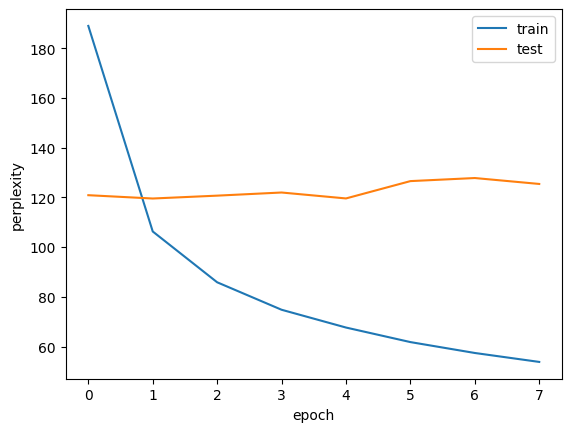

In [14]:
import copy
tr_hist, te_hist = [], []
best, best_state = 1e9, None
for ep in range(1, cfg["epochs"] + 1):
    tr = run_epoch(model, Xtr, Ytr, True)
    te = run_epoch(model, Xte, Yte, False)
    tr_hist.append(tr); te_hist.append(te)
    if te < best:                                   # remember the best weights (early stopping)
        best, best_state = te, copy.deepcopy(model.state_dict())
    print(f"epoch {ep:2d}  train ppl {math.exp(tr):8.1f}   test ppl {math.exp(te):8.1f}")
model.load_state_dict(best_state)
plt.plot([math.exp(v) for v in tr_hist], label="train"); plt.plot([math.exp(v) for v in te_hist], label="test")
plt.xlabel("epoch"); plt.ylabel("perplexity"); plt.legend(); plt.show()

### Baseline  *(TODO 9)*
A model that ignores context and only knows word frequencies is the **unigram baseline**. Using add-one smoothing,
`p(w) = (count_train(w) + 1) / (N_train + V)` where counts are over **encoded training ids** (so `<unk>` has a count).
Compute its perplexity on the same test targets `Yte`. Your RNN must beat this number to be called a language model.

In [15]:
# TODO 9: unigram_ppl
ids_tr = encode(train_tokens)                       # id training; <unk> (0) dan <eos> (1) ikut terhitung
counts = torch.bincount(ids_tr, minlength=V).float()   # (V,)  hitungan tiap id
p = (counts + 1) / (len(ids_tr) + V)                # add-one smoothing
nll = -torch.log(p[Yte]).mean()                     # p[Yte]: (n, L), probabilitas tiap target
unigram_ppl = math.exp(nll.item())

In [16]:
print(f"unigram baseline test ppl = {unigram_ppl:.1f}")
print(f"your RNN best test ppl    = {min(math.exp(v) for v in te_hist):.1f}  (epoch {int(np.argmin(te_hist))+1})")

unigram baseline test ppl = 176.7
your RNN best test ppl    = 119.5  (epoch 2)


In [17]:
k = int(np.argmin(te_hist))
print(f"best epoch {k+1} of {len(te_hist)}")
print(f"test  ppl: best {math.exp(te_hist[k]):.1f}   last {math.exp(te_hist[-1]):.1f}")
print(f"train ppl: at best epoch {math.exp(tr_hist[k]):.1f}   last {math.exp(tr_hist[-1]):.1f}")

best epoch 2 of 8
test  ppl: best 119.5   last 125.4
train ppl: at best epoch 106.3   last 53.8


## Step 6: Generate a poem  *(TODO 10)*
Feed the prompt words through the model, keep the final hidden state, then repeat: turn the last logits into a probability
distribution **using the temperature**, never allow `<unk>` (give it a logit of -1e9), sample one word with `torch.multinomial`, feed *only that word* back in together
with the hidden state. `<eos>` should be printed as a line break.

In [18]:
# TODO 10
@torch.no_grad()
def generate(model, prompt_words, n_words=60, temperature=1.0):
    model.eval()
    out = list(prompt_words)
    x = encode(prompt_words).unsqueeze(0)               # (1, P)
    logits, h = model(x)                                # (1, P, V), (1, H)
    for _ in range(n_words):
        l = logits[0, -1] / temperature                 # (V,)  logits kata terakhir, dibagi T
        l[0] = -1e9                                     # <unk> tidak boleh keluar
        probs = F.softmax(l, dim=-1)                    # (V,)  jumlah = 1
        nxt = torch.multinomial(probs, 1).item()        # satu id, dipilih acak sesuai probs
        out.append(itos[nxt])
        logits, h = model(torch.tensor([[nxt]]), h)     # hanya kata baru + h: (1,1,V), (1,H)
    return out
    # raise NotImplementedError

In [19]:
def detok(words):
    s = ""
    for w in words:
        if w == "<eos>": s += "\n\n"
        elif w in ",.;:!?": s = s.rstrip(" ") + w + " "
        else: s += w + " "
    return s

print(detok(generate(model, cfg["prompt"], 60, temperature=1.0)))

o that time things my then, some verse youth shall in that respect doth stand, and it might still you no how time lovest; your love is me, but as if new could be my proud in mistress ride. 

but, home see me for you. 

ah so is i mine forsake best is they 


## Part C: experiments (use your paper journal!)
**Write your prediction on the journal sheet before you run each cell.**

**C1. Temperature.** Generate from your prompt with temperature 0.5, 1.0 and 1.5 (same code, change one number).
**C2. When to stop.** From the curves above, which epoch had the lowest test perplexity? Is it the last one?
**C3 (optional, if time remains).** Replace your cell by `nn.LSTM` (or `nn.RNN`) with the same sizes, retrain, compare test perplexity.

In [20]:
# C1. Temperature
for T in (0.5, 1.0, 1.5):
    torch.manual_seed(0)
    w = generate(model, cfg["prompt"], 50, temperature=T)[-50:]
    print(f"T={T}: kata unik {len(set(w))}/{len(w)}")
    print(detok(w))

T=0.5: kata unik 29/50
, to whom the time of the day, to morrow, and i journey, and all the day of your true thy name; but when i am, and they have to make the least of my heart, and i have seen to the very world's 
T=1.0: kata unik 37/50
holds to, as thy will, or now things some, to eat journey? then when i have seen, and thy sweet minds to wrong. 

when what they all of this hath decay, to say this attending, and you to the proud world's 
T=1.5: kata unik 48/50
holds to, as thy will sorrow nothing now things tied graces she must journey? rhyme within those have they mourn yourself thy lusty minds fears wrong virtuous doth hence what they all of this hath decay but is done control attending toil cruel sweet mind taught out woe 


###  C2. When to Stop
At baseline cell (TODO 9), written:

> unigram baseline test ppl = 176.7  
> your RNN best test ppl    = 119.5  (epoch 2)

#### From the curves above, which epoch had the lowest test perplexity? Is it the last one?

> Epoch 2 had the lowest test perplexity (119.5), not the last one (epoch 8: 125.4). 

From epoch 2 to 8 the train perplexity kept falling (106.3 → 53.8) while the test perplexity rose (119.5 → 125.4): the model starts memorising the tiny corpus (overfitting), so early stopping at epoch 2 gives the best generalisation. 119.5 is also clearly below the unigram baseline (176.7), so the RNN uses context.

In [21]:
# C3. nn.LSTM
class MyLSTM(nn.Module):
    def __init__(self, V, E, H):
        super().__init__()
        self.emb  = nn.Embedding(V, E)
        self.drop = nn.Dropout(0.5)
        self.rnn  = nn.LSTM(E, H, batch_first=True)
        self.out  = nn.Linear(H, V)

    def forward(self, x, state=None):
        o, state = self.rnn(self.drop(self.emb(x)), state)   # o: (B, L, H)
        return self.out(self.drop(o)), state

In [22]:
# Retrain dengan ukuran, lr, epoch yang sama
lstm = MyLSTM(V, cfg["emb"], cfg["hidden"])
opt = torch.optim.Adam(lstm.parameters(), lr=cfg["lr"])    # run_epoch memakai `opt` global
l_tr, l_te = [], []
l_best, l_state = 1e9, None
for ep in range(1, cfg["epochs"] + 1):
    tr = run_epoch(lstm, Xtr, Ytr, True)
    te = run_epoch(lstm, Xte, Yte, False)
    l_tr.append(tr); l_te.append(te)
    if te < l_best:
        l_best, l_state = te, copy.deepcopy(lstm.state_dict())
    print(f"epoch {ep:2d}  train ppl {math.exp(tr):8.1f}   test ppl {math.exp(te):8.1f}")
lstm.load_state_dict(l_state)

epoch  1  train ppl    192.2   test ppl    118.0
epoch  2  train ppl    110.8   test ppl    112.9
epoch  3  train ppl     87.3   test ppl    115.1
epoch  4  train ppl     74.8   test ppl    118.8
epoch  5  train ppl     66.3   test ppl    123.2
epoch  6  train ppl     60.2   test ppl    125.6
epoch  7  train ppl     55.2   test ppl    129.7
epoch  8  train ppl     51.4   test ppl    135.4


<All keys matched successfully>

model           params  best ep  test ppl
manual RNN      281394        2     119.5
nn.LSTM         356018        2     112.9
unigram baseline test ppl = 176.7


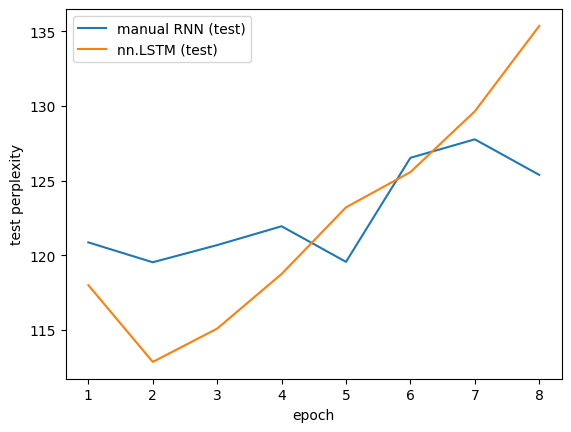

In [23]:
# Perbandingan
n_rnn  = sum(p.numel() for p in model.parameters())
n_lstm = sum(p.numel() for p in lstm.parameters())
print(f"{'model':12s}{'params':>10s}{'best ep':>9s}{'test ppl':>10s}")
print(f"{'manual RNN':12s}{n_rnn:10d}{int(np.argmin(te_hist))+1:9d}{math.exp(min(te_hist)):10.1f}")
print(f"{'nn.LSTM':12s}{n_lstm:10d}{int(np.argmin(l_te))+1:9d}{math.exp(min(l_te)):10.1f}")
print(f"unigram baseline test ppl = {unigram_ppl:.1f}")

plt.plot(range(1, len(te_hist)+1), [math.exp(v) for v in te_hist], label="manual RNN (test)")
plt.plot(range(1, len(l_te)+1),   [math.exp(v) for v in l_te],   label="nn.LSTM (test)")
plt.xlabel("epoch"); plt.ylabel("test perplexity"); plt.legend(); plt.show()

> nn.LSTM reached a lower best test perplexity than the handwritten RNN (112.9 vs 119.5, both at epoch 2, both well below the unigram baseline of 176.7) for about 27% more parameters (356,018 vs 281,394); both then overfit (LSTM: 112.9 → 135.4 by epoch 8), so with only 146 training sonnets the stopping epoch matters at least as much as the cell type. This is a single run, so the ~6-point gap is suggestive rather than conclusive.